# ERA5 vs Published Ground-Based Wind Speed: Hour-by-Hour Aligned Comparison (with Mean Offset)

This notebook performs a direct hour-by-hour comparison between **ERA5 10m wind speed** and **ALMA ground-based weather station observations** for the years 2001 and 2002. 

To account for the systematic underestimation of wind speeds by ERA5 in this high-altitude complex terrain, a **mean offset** has been calculated and applied to the ERA5 dataset. This matches the means of the two datasets and allows for a more realistic comparison of variations, distributions, and quantiles.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print("Libraries loaded successfully! ✔")

Libraries loaded successfully! ✔


In [2]:
# ============================================================
# 2. LOAD PUBLISHED GROUND-BASED DATA
# ============================================================
pub_path = r"../data/exports/alma_published_timeseries.csv"
df_pub = pd.read_csv(pub_path, parse_dates=['datetime'])

# Drop rows with missing speed values (Column 7 / 'speed' is wind speed in m/s)
df_pub = df_pub.dropna(subset=['speed'])
print(f"Loaded {len(df_pub):,} valid ground-based hourly records.")
print(df_pub[['datetime', 'speed', 'direction']].head())

Loaded 15,632 valid ground-based hourly records.
             datetime  speed  direction
0 2001-01-01 00:00:00    9.8      268.0
1 2001-01-01 01:00:00    6.6      260.0
2 2001-01-01 02:00:00    3.7      271.0
3 2001-01-01 03:00:00    1.6      301.0
4 2001-01-01 04:00:00    0.2      313.0


In [3]:
# ============================================================
# 3. LOAD ERA5 DATA FOR ALMA SITE
# ============================================================
ALMA_LAT = -23.029
ALMA_LON = -67.755

chile_files = sorted(glob.glob(r"../data/raw/chile/chile_*.nc"))
print(f"Found {len(chile_files)} ERA5 NetCDF files.")

era5_records = []
for f in chile_files:
    with xr.open_dataset(f) as ds:
        # Extract nearest grid point to ALMA site
        point_ds = ds.sel(latitude=ALMA_LAT, longitude=ALMA_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        # Calculate 10m wind speed in m/s from components
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': point_ds['valid_time'].values,
            'era5_speed': ws10
        })
        era5_records.append(df_pt)

df_era5 = pd.concat(era5_records, ignore_index=True)
print(f"Loaded {len(df_era5):,} ERA5 hourly records.")
print(df_era5.head())

Found 24 ERA5 NetCDF files.


Loaded 17,520 ERA5 hourly records.
             datetime  era5_speed
0 2001-01-01 00:00:00    3.589680
1 2001-01-01 01:00:00    1.797550
2 2001-01-01 02:00:00    1.867238
3 2001-01-01 03:00:00    1.000621
4 2001-01-01 04:00:00    0.164233


In [4]:
# ============================================================
# 4. ALIGN DATASETS (INNER JOIN ON DATETIME) & APPLY MEAN OFFSET
# ============================================================
# This ensures we only compare timestamps that exist in both datasets
merged_df = pd.merge(df_pub, df_era5, on='datetime', how='inner')
merged_df = merged_df.dropna(subset=['speed', 'era5_speed'])
merged_df = merged_df.sort_values('datetime').reset_index(drop=True)

# Calculate mean bias and create offset ERA5 speed
# bias = mean(era5) - mean(ground)
bias_val = merged_df['era5_speed'].mean() - merged_df['speed'].mean()
merged_df['era5_speed_offset'] = merged_df['era5_speed'] - bias_val

print(f"Aligned dataset size: {len(merged_df):,} records.")
print(f"Temporal coverage: {merged_df['datetime'].min()} to {merged_df['datetime'].max()}")
print(f"Calculated mean bias: {bias_val:.4f} m/s (ERA5 is offset by subtracting this bias, i.e., adding {-bias_val:.4f} m/s)")

Aligned dataset size: 15,632 records.
Temporal coverage: 2001-01-01 00:00:00 to 2002-12-31 23:00:00
Calculated mean bias: -4.0626 m/s (ERA5 is offset by subtracting this bias, i.e., adding 4.0626 m/s)


In [5]:
# ============================================================
# 5. CALCULATE COMPARISON METRICS
# ============================================================
diff_orig = merged_df['era5_speed'] - merged_df['speed']
rmse_orig = np.sqrt((diff_orig ** 2).mean())
bias_orig = diff_orig.mean()
mae_orig = diff_orig.abs().mean()
corr_orig = merged_df['speed'].corr(merged_df['era5_speed'])

diff_offset = merged_df['era5_speed_offset'] - merged_df['speed']
rmse_offset = np.sqrt((diff_offset ** 2).mean())
bias_offset = diff_offset.mean()
mae_offset = diff_offset.abs().mean()
corr_offset = merged_df['speed'].corr(merged_df['era5_speed_offset'])

print("--- Aligned Wind Speed Comparison Metrics ---")
print(f"Mean Ground-Based Speed : {merged_df['speed'].mean():.4f} m/s")
print(f"Mean ERA5 Speed (Orig)  : {merged_df['era5_speed'].mean():.4f} m/s")
print(f"Mean ERA5 Speed (Offset): {merged_df['era5_speed_offset'].mean():.4f} m/s")
print("")
print("Metrics for Original ERA5 vs Ground-Based:")
print(f"  Mean Bias Error (MBE)   : {bias_orig:.4f} m/s (Negative means ERA5 underestimates)")
print(f"  Mean Absolute Error (MAE): {mae_orig:.4f} m/s")
print(f"  Root Mean Sq. Error (RMSE): {rmse_orig:.4f} m/s")
print(f"  Pearson Correlation     : {corr_orig:.4f}")
print("")
print("Metrics for Offset ERA5 vs Ground-Based:")
print(f"  Mean Bias Error (MBE)   : {bias_offset:.4f} m/s (Should be zero)")
print(f"  Mean Absolute Error (MAE): {mae_offset:.4f} m/s")
print(f"  Root Mean Sq. Error (RMSE): {rmse_offset:.4f} m/s")
print(f"  Pearson Correlation     : {corr_offset:.4f} (Should be identical to original)")

--- Aligned Wind Speed Comparison Metrics ---
Mean Ground-Based Speed : 6.5501 m/s
Mean ERA5 Speed (Orig)  : 2.4875 m/s
Mean ERA5 Speed (Offset): 6.5501 m/s

Metrics for Original ERA5 vs Ground-Based:
  Mean Bias Error (MBE)   : -4.0626 m/s (Negative means ERA5 underestimates)
  Mean Absolute Error (MAE): 4.1247 m/s
  Root Mean Sq. Error (RMSE): 5.0299 m/s
  Pearson Correlation     : 0.6734

Metrics for Offset ERA5 vs Ground-Based:
  Mean Bias Error (MBE)   : 0.0000 m/s (Should be zero)
  Mean Absolute Error (MAE): 2.3007 m/s
  Root Mean Sq. Error (RMSE): 2.9658 m/s
  Pearson Correlation     : 0.6734 (Should be identical to original)


In [6]:
# ============================================================
# 6. OVERALL PERCENTILE COMPARISON
# ============================================================
percentiles = [50, 90, 95, 99]
pub_pcts = [merged_df['speed'].quantile(p/100) for p in percentiles]
era5_pcts = [merged_df['era5_speed'].quantile(p/100) for p in percentiles]
era5_offset_pcts = [merged_df['era5_speed_offset'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'ERA5 Original (m/s)': era5_pcts,
    'ERA5 Offset (m/s)': era5_offset_pcts,
    'Orig Diff (m/s)': [e - g for g, e in zip(pub_pcts, era5_pcts)],
    'Offset Diff (m/s)': [e - g for g, e in zip(pub_pcts, era5_offset_pcts)],
    'Ratio (Offset/Ground)': [e / g if g != 0 else np.nan for g, e in zip(pub_pcts, era5_offset_pcts)]
})
print("--- Percentile Comparison Table ---")
print(df_pct.to_string(index=False))

--- Percentile Comparison Table ---
Percentile  Ground-Based (m/s)  ERA5 Original (m/s)  ERA5 Offset (m/s)  Orig Diff (m/s)  Offset Diff (m/s)  Ratio (Offset/Ground)
       P50                 6.0             1.867969           5.930553        -4.132031          -0.069447               0.988426
       P90                11.8             5.789335           9.851919        -6.010665          -1.948081               0.834908
       P95                13.6             6.546185          10.608769        -7.053815          -2.991231               0.780057
       P99                17.6             8.061701          12.124286        -9.538299          -5.475714               0.688880


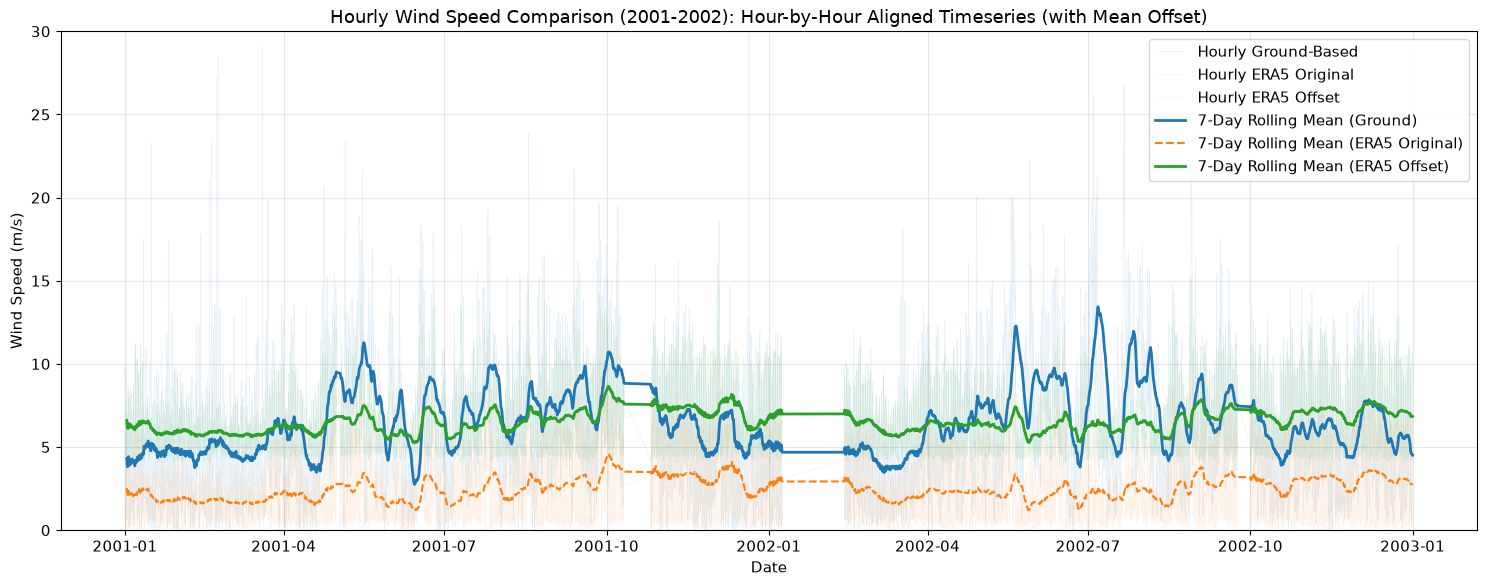

In [7]:
# ============================================================
# 7. PLOT TIME SERIES WITH 7-DAY ROLLING AVERAGE
# ============================================================
plt.figure(figsize=(15, 6))
# Plot hourly speeds in faint color to show raw variance
plt.plot(merged_df['datetime'], merged_df['speed'], color='#1f77b4', alpha=0.1, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed'], color='#ff7f0e', alpha=0.1, label='Hourly ERA5 Original', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed_offset'], color='#2ca02c', alpha=0.1, label='Hourly ERA5 Offset', linewidth=0.5)

# 7-day rolling average (aligned hourly data points)
# Note: since 1 week is ~168 hours, we roll by 168 observations
roll_window = 168
plt.plot(merged_df['datetime'], merged_df['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(merged_df['datetime'], merged_df['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (ERA5 Original)', linewidth=1.5, linestyle='--')
plt.plot(merged_df['datetime'], merged_df['era5_speed_offset'].rolling(roll_window, min_periods=24).mean(), 
         color='#2ca02c', label='7-Day Rolling Mean (ERA5 Offset)', linewidth=2.0)

plt.title('Hourly Wind Speed Comparison (2001-2002): Hour-by-Hour Aligned Timeseries (with Mean Offset)')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../data/exports/aligned_timeseries_comparison.png', dpi=150)
plt.show()

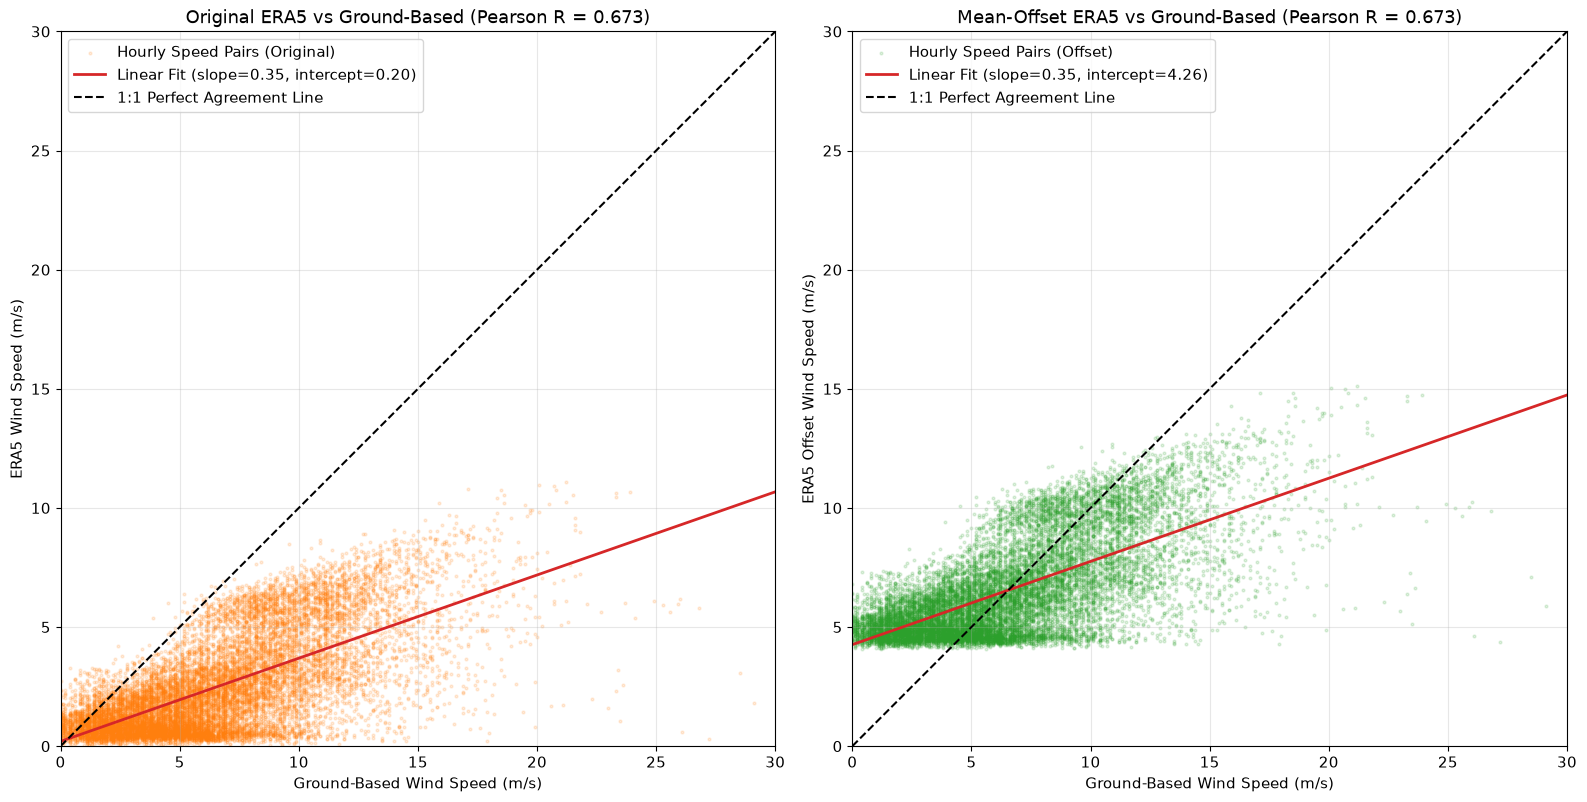

In [8]:
# ============================================================
# 8. SCATTER PLOT AND CORRELATION
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Panel A: Original ERA5
axes[0].scatter(merged_df['speed'], merged_df['era5_speed'], alpha=0.15, s=4, color='#ff7f0e', label='Hourly Speed Pairs (Original)')
slope_orig, intercept_orig = np.polyfit(merged_df['speed'], merged_df['era5_speed'], 1)
x_vals = np.linspace(0, 30, 100)
axes[0].plot(x_vals, slope_orig * x_vals + intercept_orig, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope_orig:.2f}, intercept={intercept_orig:.2f})')
axes[0].plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement Line', linewidth=1.5)
axes[0].set_title(f'Original ERA5 vs Ground-Based (Pearson R = {corr_orig:.3f})')
axes[0].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[0].set_ylabel('ERA5 Wind Speed (m/s)')
axes[0].set_xlim(0, 30)
axes[0].set_ylim(0, 30)
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(loc='upper left')

# Panel B: Offset ERA5
axes[1].scatter(merged_df['speed'], merged_df['era5_speed_offset'], alpha=0.15, s=4, color='#2ca02c', label='Hourly Speed Pairs (Offset)')
slope_offset, intercept_offset = np.polyfit(merged_df['speed'], merged_df['era5_speed_offset'], 1)
axes[1].plot(x_vals, slope_offset * x_vals + intercept_offset, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope_offset:.2f}, intercept={intercept_offset:.2f})')
axes[1].plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement Line', linewidth=1.5)
axes[1].set_title(f'Mean-Offset ERA5 vs Ground-Based (Pearson R = {corr_offset:.3f})')
axes[1].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[1].set_ylabel('ERA5 Offset Wind Speed (m/s)')
axes[1].set_xlim(0, 30)
axes[1].set_ylim(0, 30)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.savefig('../data/exports/aligned_scatter_correlation.png', dpi=150)
plt.show()

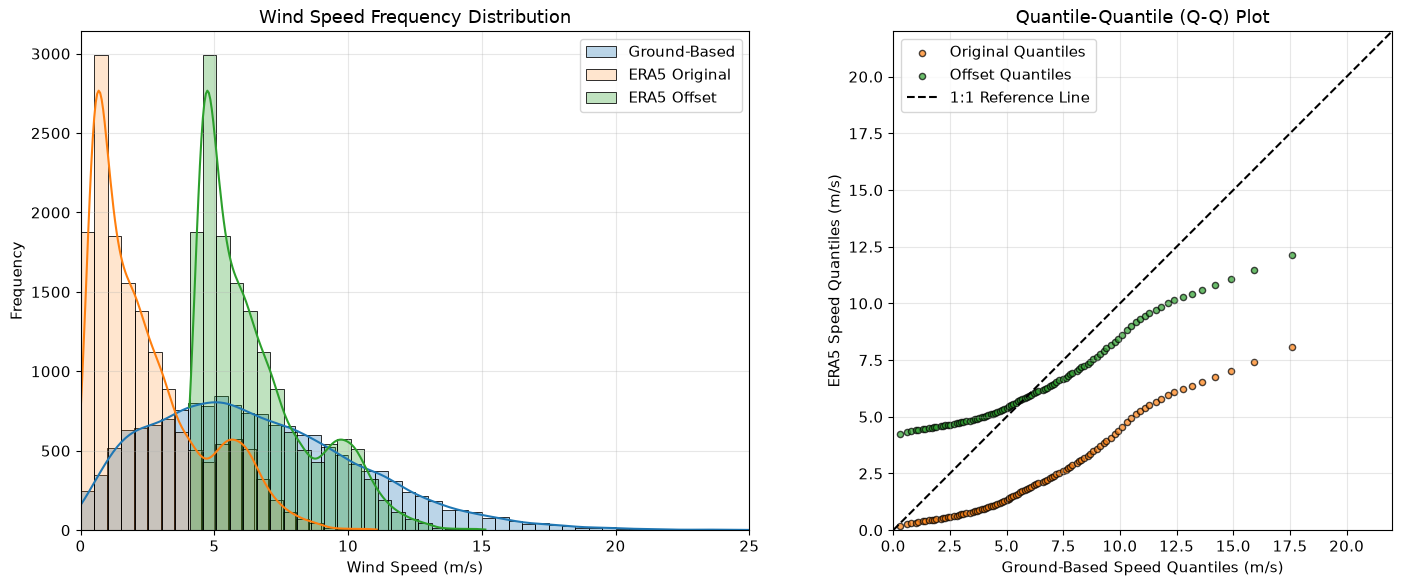

In [9]:
# ============================================================
# 9. DISTRIBUTION COMPARISON (HISTOGRAMS & Q-Q PLOT)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A: Histograms / KDEs
sns.histplot(merged_df['speed'], color='#1f77b4', alpha=0.3, label='Ground-Based', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed'], color='#ff7f0e', alpha=0.2, label='ERA5 Original', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed_offset'], color='#2ca02c', alpha=0.3, label='ERA5 Offset', kde=True, binwidth=0.5, ax=axes[0])
axes[0].set_title('Wind Speed Frequency Distribution')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Panel B: Quantile-Quantile (Q-Q) Plot
# We plot sorted percentiles from 1 to 99 to check distributional mapping
q_values = np.linspace(0.01, 0.99, 99)
q_pub = merged_df['speed'].quantile(q_values)
q_era5 = merged_df['era5_speed'].quantile(q_values)
q_era5_offset = merged_df['era5_speed_offset'].quantile(q_values)

axes[1].scatter(q_pub, q_era5, color='#ff7f0e', edgecolor='k', s=20, alpha=0.7, label='Original Quantiles')
axes[1].scatter(q_pub, q_era5_offset, color='#2ca02c', edgecolor='k', s=20, alpha=0.7, label='Offset Quantiles')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('ERA5 Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/exports/aligned_distribution_comparison.png', dpi=150)
plt.show()

--- Aligned Monthly Means (Excluding ground gaps) ---
 year  month  mean_pub  mean_era5  mean_era5_offset  count
 2001      1  4.670917   1.997699          6.060283    698
 2001      2  4.792920   1.750296          5.812880    565
 2001      3  5.440557   1.939577          6.002161    646
 2001      4  6.149067   2.199389          6.261974    697
 2001      5  7.944653   2.290840          6.353424    692
 2001      6  6.477437   2.101699          6.164284    718
 2001      7  7.375672   2.332597          6.395181    744
 2001      8  6.839481   2.492284          6.554869    732
 2001      9  8.483472   3.175502          7.238086    720
 2001     10  8.178400   3.522260          7.584845    375
 2001     11  5.821702   3.153679          7.216264    705
 2001     12  5.656618   2.911721          6.974305    680
 2002      1  4.740936   2.924759          6.987344    171
 2002      2  4.730491   2.466761          6.529346    387
 2002      3  4.717410   1.921300          5.983885    695
 2

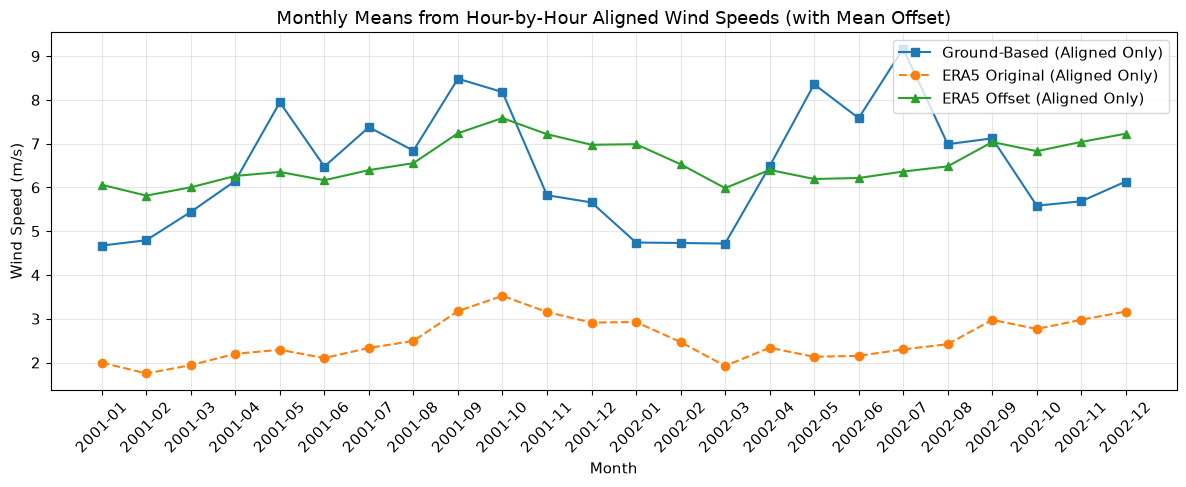

In [10]:
# ============================================================
# 10. RECALCULATED MONTHLY STATS OVER ALIGNED DATA ONLY
# ============================================================
# Group by year/month to see the monthly means *only* on dates where both had valid observations
merged_df['year'] = merged_df['datetime'].dt.year
merged_df['month'] = merged_df['datetime'].dt.month

monthly_aligned = merged_df.groupby(['year', 'month']).agg(
    mean_pub=('speed', 'mean'),
    mean_era5=('era5_speed', 'mean'),
    mean_era5_offset=('era5_speed_offset', 'mean'),
    count=('speed', 'count')
).reset_index()

print("--- Aligned Monthly Means (Excluding ground gaps) ---")
print(monthly_aligned.to_string(index=False))

# Plot monthly means
plt.figure(figsize=(12, 5))
monthly_aligned['date_str'] = monthly_aligned['year'].astype(str) + '-' + monthly_aligned['month'].astype(str).str.zfill(2)
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_pub'], marker='s', color='#1f77b4', label='Ground-Based (Aligned Only)')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_era5'], marker='o', color='#ff7f0e', linestyle='--', label='ERA5 Original (Aligned Only)')
plt.plot(monthly_aligned['date_str'], monthly_aligned['mean_era5_offset'], marker='^', color='#2ca02c', label='ERA5 Offset (Aligned Only)')
plt.title('Monthly Means from Hour-by-Hour Aligned Wind Speeds (with Mean Offset)')
plt.xlabel('Month')
plt.ylabel('Wind Speed (m/s)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../data/exports/aligned_monthly_means.png', dpi=150)
plt.show()